In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree
from sklearn import preprocessing
from sklearn import ensemble
from sklearn import metrics
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [74]:
data = pd.read_csv("health_lifestyle_dataset.csv")
data = data.drop("ID" , axis=1)
data

,Age,Gender,Height_cm,Weight_kg,BMI,Daily_Steps,Calories_Intake,Hours_of_Sleep,Heart_Rate,Blood_Pressure,Exercise_Hours_per_Week,Smoker,Alcohol_Consumption_per_Week,Diabetic,Heart_Disease
0,56,Male,164,81,30.72,5134,1796,8.6,102,137/72,8.1,No,7,No,No
1,69,Male,156,82,20.86,12803,1650,4.5,103,129/65,3.7,No,7,No,No
2,46,Female,158,65,30.93,16408,1756,4.3,74,127/68,3.2,Yes,0,No,No
3,32,Male,197,87,31.19,18420,2359,4.1,116,125/86,8.5,No,5,No,No
4,60,Male,157,63,29.37,17351,2556,5.1,111,100/64,8.5,Yes,8,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,18,Male,179,116,31.67,10095,2667,4.6,79,108/63,6.3,No,5,No,No
996,35,Female,170,114,23.88,11361,2351,7.2,54,98/75,2.9,No,3,No,Yes
997,49,Female,169,85,23.44,9531,2416,4.5,80,125/65,7.6,No,4,No,No
998,64,Male,155,74,22.34,5270,2080,5.8,101,129/86,5.4,No,4,No,No


In [75]:
data.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Daily_Steps,Calories_Intake,Hours_of_Sleep,Heart_Rate,Blood_Pressure,Exercise_Hours_per_Week,Smoker,Alcohol_Consumption_per_Week,Diabetic,Heart_Disease
0,56,Male,164,81,30.72,5134,1796,8.6,102,137/72,8.1,No,7,No,No
1,69,Male,156,82,20.86,12803,1650,4.5,103,129/65,3.7,No,7,No,No
2,46,Female,158,65,30.93,16408,1756,4.3,74,127/68,3.2,Yes,0,No,No
3,32,Male,197,87,31.19,18420,2359,4.1,116,125/86,8.5,No,5,No,No
4,60,Male,157,63,29.37,17351,2556,5.1,111,100/64,8.5,Yes,8,No,No


In [76]:
data.tail()

,Age,Gender,Height_cm,Weight_kg,BMI,Daily_Steps,Calories_Intake,Hours_of_Sleep,Heart_Rate,Blood_Pressure,Exercise_Hours_per_Week,Smoker,Alcohol_Consumption_per_Week,Diabetic,Heart_Disease
995,18,Male,179,116,31.67,10095,2667,4.6,79,108/63,6.3,No,5,No,No
996,35,Female,170,114,23.88,11361,2351,7.2,54,98/75,2.9,No,3,No,Yes
997,49,Female,169,85,23.44,9531,2416,4.5,80,125/65,7.6,No,4,No,No
998,64,Male,155,74,22.34,5270,2080,5.8,101,129/86,5.4,No,4,No,No
999,66,Female,171,86,20.64,10906,1284,8.5,72,118/83,1.3,No,1,No,No


In [77]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Age                           1000 non-null   int64  
 1   Gender                        1000 non-null   str    
 2   Height_cm                     1000 non-null   int64  
 3   Weight_kg                     1000 non-null   int64  
 4   BMI                           1000 non-null   float64
 5   Daily_Steps                   1000 non-null   int64  
 6   Calories_Intake               1000 non-null   int64  
 7   Hours_of_Sleep                1000 non-null   float64
 8   Heart_Rate                    1000 non-null   int64  
 9   Blood_Pressure                1000 non-null   str    
 10  Exercise_Hours_per_Week       1000 non-null   float64
 11  Smoker                        1000 non-null   str    
 12  Alcohol_Consumption_per_Week  1000 non-null   int64  
 13  Diabetic       

In [78]:
data.isnull().sum()

Age                             0
Gender                          0
Height_cm                       0
Weight_kg                       0
BMI                             0
Daily_Steps                     0
Calories_Intake                 0
Hours_of_Sleep                  0
Heart_Rate                      0
Blood_Pressure                  0
Exercise_Hours_per_Week         0
Smoker                          0
Alcohol_Consumption_per_Week    0
Diabetic                        0
Heart_Disease                   0
dtype: int64

In [79]:
data.duplicated().sum()

np.int64(0)

In [80]:


# پیدا کردن ستون‌هایی که نوع آن‌ها متنی (object/str) است
cat_cols = data.select_dtypes(include=["object"]).columns

oe = OrdinalEncoder()
data[cat_cols] = oe.fit_transform(data[cat_cols])


C:\Users\sama\AppData\Local\Temp\ipykernel_5512\2059905026.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data.select_dtypes(include=["object"]).columns


In [81]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Age                           1000 non-null   int64  
 1   Gender                        1000 non-null   float64
 2   Height_cm                     1000 non-null   int64  
 3   Weight_kg                     1000 non-null   int64  
 4   BMI                           1000 non-null   float64
 5   Daily_Steps                   1000 non-null   int64  
 6   Calories_Intake               1000 non-null   int64  
 7   Hours_of_Sleep                1000 non-null   float64
 8   Heart_Rate                    1000 non-null   int64  
 9   Blood_Pressure                1000 non-null   float64
 10  Exercise_Hours_per_Week       1000 non-null   float64
 11  Smoker                        1000 non-null   float64
 12  Alcohol_Consumption_per_Week  1000 non-null   int64  
 13  Diabetic       

In [82]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,49.85700,18.114267,18.0,35.000,50.0,66.00,79.00
Gender,1000.0,0.52300,0.499721,0.0,0.000,1.0,1.00,1.00
Height_cm,1000.0,174.74500,14.541920,150.0,162.000,175.0,187.00,199.00
Weight_kg,1000.0,84.35200,20.065960,50.0,68.000,84.0,101.00,119.00
BMI,1000.0,26.72951,4.786341,18.5,22.600,26.8,30.85,34.98
Daily_Steps,1000.0,10717.03400,5444.707891,1016.0,6028.250,10898.0,15253.25,19931.00
Calories_Intake,1000.0,2327.11700,657.847942,1201.0,1745.750,2328.5,2880.00,3498.00
Hours_of_Sleep,1000.0,6.90990,1.779640,4.0,5.300,6.9,8.40,10.00
Heart_Rate,1000.0,84.71000,20.130155,50.0,67.000,84.0,103.00,119.00
Blood_Pressure,1000.0,365.66700,212.270278,0.0,183.750,364.5,551.25,731.00


In [83]:
print(data["Alcohol_Consumption_per_Week"].value_counts())
print("-------------------------------------------------")

print(data["Smoker"].value_counts())
print("-------------------------------------------------")

print(data["Heart_Disease"].value_counts())
print("-------------------------------------------------")

Alcohol_Consumption_per_Week
3    108
9    106
8    105
1    105
5    103
2    101
4     98
6     96
7     95
0     83
Name: count, dtype: int64
-------------------------------------------------
Smoker
0.0    809
1.0    191
Name: count, dtype: int64
-------------------------------------------------
Heart_Disease
0.0    907
1.0     93
Name: count, dtype: int64
-------------------------------------------------


In [84]:
idx = list(data["Heart_Disease"].value_counts().index)
count = data["Heart_Disease"].value_counts()

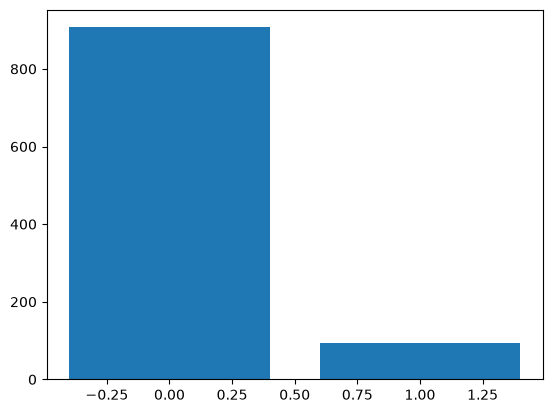

In [85]:
idx  = [0 , 1]
count = data["Heart_Disease"].value_counts()


plt.bar([0,1],data["Heart_Disease"].value_counts())
plt.show()

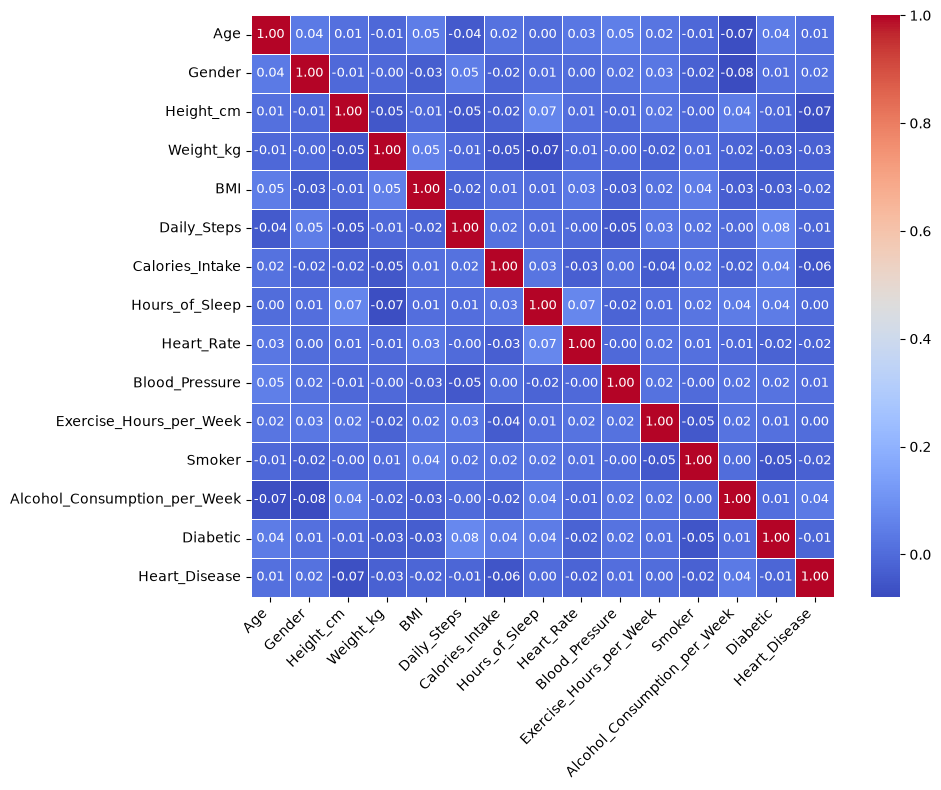

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

# ۱. تعیین سایز بزرگ‌تر برای خوانایی بهتر
plt.figure(figsize=(10, 8))

# ۲. رسم هیت‌مپ با تنظیمات بهینه (دو رقم اعشار و رنگ مناسب)
sns.heatmap(
    data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    annot_kws={"size": 9},
)

# ۳. چرخش نام ستون‌ها برای جلوگیری از روی هم افتادن
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()  # تنظیم خودکار حاشیه‌ها
plt.show()


In [87]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,49.85700,18.114267,18.0,35.000,50.0,66.00,79.00
Gender,1000.0,0.52300,0.499721,0.0,0.000,1.0,1.00,1.00
Height_cm,1000.0,174.74500,14.541920,150.0,162.000,175.0,187.00,199.00
Weight_kg,1000.0,84.35200,20.065960,50.0,68.000,84.0,101.00,119.00
BMI,1000.0,26.72951,4.786341,18.5,22.600,26.8,30.85,34.98
Daily_Steps,1000.0,10717.03400,5444.707891,1016.0,6028.250,10898.0,15253.25,19931.00
Calories_Intake,1000.0,2327.11700,657.847942,1201.0,1745.750,2328.5,2880.00,3498.00
Hours_of_Sleep,1000.0,6.90990,1.779640,4.0,5.300,6.9,8.40,10.00
Heart_Rate,1000.0,84.71000,20.130155,50.0,67.000,84.0,103.00,119.00
Blood_Pressure,1000.0,365.66700,212.270278,0.0,183.750,364.5,551.25,731.00


In [90]:
x =data.drop("Heart_Disease" , axis=1)
y = data["Heart_Disease"]
x_train , x_test , y_train , y_test = train_test_split(
    x ,y , random_state=42 , test_size=0.2 )

In [91]:
model_tree = tree.DecisionTreeClassifier()
model_tree.fit(x_train , y_train)
y_pred_tree = model_tree.predict(x_test)
metrics.accuracy_score(y_test, y_pred_tree) * 100

81.5

In [92]:
model_forest = ensemble.RandomForestClassifier()
model_forest.fit(x_train , y_train)
y_pred_forest  =model_forest.predict(x_test)
metrics.accuracy_score(y_test, y_pred_tree) * 100

81.5